In [2]:
import os, sys, time, json, shutil, subprocess, warnings
warnings.filterwarnings("ignore")

try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
if shutil.which("java") is None:
    subprocess.run("apt-get -qq install -y openjdk-17-jdk-headless > /dev/null", shell=True, check=True)

from google.colab import drive
drive.mount("/content/drive")
PERSIST_DIR = "/content/drive/MyDrive/7006SCN_GSOD"
SCRATCH_DIR = "/content/gsod_scratch"
LOCAL_DIR   = "/content/gsod_local"

def sp(path):
    return path

RAW_DIR     = SCRATCH_DIR + "/raw_csv"
ARCHIVE_DIR = PERSIST_DIR + "/archives"
PARQUET_RAW = LOCAL_DIR + "/parquet/gsod_raw"
FEATURES    = LOCAL_DIR + "/parquet/gsod_features"
PRED_DIR    = LOCAL_DIR + "/parquet/predictions"
MODELS_DIR  = LOCAL_DIR + "/models"
OUT_DIR     = PERSIST_DIR + "/outputs"
for d in [PERSIST_DIR, SCRATCH_DIR, LOCAL_DIR, ARCHIVE_DIR, MODELS_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

def backup_to_drive(local_path):
    dest = local_path.replace(LOCAL_DIR, PERSIST_DIR)
    shutil.rmtree(dest, ignore_errors=True)
    shutil.copytree(local_path, dest)
    print("backed up ->", dest)

def restore_from_drive(local_path):
    if not os.path.exists(local_path):
        shutil.copytree(local_path.replace(LOCAL_DIR, PERSIST_DIR), local_path)
        print("restored <-", local_path)

YEARS       = [2020, 2021, 2022, 2023]
TRAIN_YEARS = [2020, 2021, 2022]
TEST_YEAR   = 2023
SEED        = 42

from pyspark.sql import SparkSession, functions as F, Window
from pyspark import StorageLevel
TOTAL_RAM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
DRIVER_MEM = f"{max(2, int(TOTAL_RAM_GB * 0.7))}g"

spark = (SparkSession.builder
         .master("local[*]")
         .appName("7006SCN_GSOD_Task4")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
         .config("spark.sql.files.maxPartitionBytes", str(128 * 1024 * 1024))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def n_partitions(df):
    return df.rdd.getNumPartitions()

def safe_persist(df, name, level=StorageLevel.MEMORY_AND_DISK):
    out = df.persist(level)
    out.count()
    return out

def save_csv(pdf, name):
    path = f"{OUT_DIR}/{name}"
    pdf.to_csv(path, index=False)
    print("saved ->", path)

print(f"Spark {spark.version} | master={spark.sparkContext.master} | cores={spark.sparkContext.defaultParallelism} "
      f"| driver memory={DRIVER_MEM} | RAM={TOTAL_RAM_GB:.1f} GB")
print("PERSIST_DIR =", PERSIST_DIR)

restore_from_drive(FEATURES)
restore_from_drive(f"{MODELS_DIR}/prep_pipeline")

Mounted at /content/drive
Spark 4.0.4 | master=local[*] | cores=2 | driver memory=8g | RAM=12.7 GB
PERSIST_DIR = /content/drive/MyDrive/7006SCN_GSOD
restored <- /content/gsod_local/parquet/gsod_features
restored <- /content/gsod_local/models/prep_pipeline


In [3]:
sc = spark.sparkContext
print("Application id :", sc.applicationId)
print("Spark UI       :", sc.uiWebUrl)
from google.colab.output import eval_js
print("Open Spark UI  :", eval_js("google.colab.kernel.proxyPort(4040)") + "jobs/")

Application id : local-1793069602072
Spark UI       : http://7a00a37d45f0:4040
Open Spark UI  : https://4040-m-s-use1d1-t0d2uc8ozab2-d.us-east1.prod.r.colab.devjobs/


In [4]:
import pandas as pd, numpy as np, urllib.request
conf_keys = ["spark.master", "spark.driver.memory", "spark.executor.memory", "spark.executor.cores",
             "spark.sql.shuffle.partitions", "spark.sql.adaptive.enabled", "spark.serializer",
             "spark.sql.files.maxPartitionBytes", "spark.default.parallelism"]
conf = dict(sc.getConf().getAll())
cfg = pd.DataFrame([{"setting": k, "value": conf.get(k, spark.conf.get(k, "(default)") if k.startswith("spark.sql") else "(default)")}
                    for k in conf_keys])
cfg = pd.concat([cfg, pd.DataFrame([
    {"setting": "defaultParallelism (cores available)", "value": sc.defaultParallelism},
    {"setting": "machine CPU count", "value": os.cpu_count()},
    {"setting": "machine RAM (GB)", "value": round(TOTAL_RAM_GB, 1)},
    {"setting": "Spark version", "value": spark.version}])], ignore_index=True)
print(cfg.to_string(index=False))
save_csv(cfg, "task4_resource_config.csv")

                             setting                                      value
                        spark.master                                   local[*]
                 spark.driver.memory                                         8g
               spark.executor.memory                                  (default)
                spark.executor.cores                                  (default)
        spark.sql.shuffle.partitions                                         64
          spark.sql.adaptive.enabled                                       true
                    spark.serializer org.apache.spark.serializer.KryoSerializer
   spark.sql.files.maxPartitionBytes                                  134217728
           spark.default.parallelism                                  (default)
defaultParallelism (cores available)                                          2
                   machine CPU count                                          2
                    machine RAM (GB)    

In [5]:
features = spark.read.parquet(sp(FEATURES))
N = features.count()
print(f"Feature table: {N:,} rows, {n_partitions(features)} input partitions")
EXPERIMENTS = []

Feature table: 15,899,103 rows, 7 input partitions


In [6]:
def station_agg():
    return (features.groupBy("STATION")
            .agg(F.avg("TEMP").alias("t"), F.sum("label").alias("ext"), F.count("*").alias("n"))
            .agg(F.sum("n")).collect())

spark.conf.set("spark.sql.adaptive.enabled", "false")
shuffle_rows = []
for p in [8, 32, 64, 200, 400]:
    spark.conf.set("spark.sql.shuffle.partitions", str(p))
    station_agg()
    t0 = time.perf_counter(); station_agg(); t = time.perf_counter() - t0
    shuffle_rows.append({"shuffle_partitions": p, "seconds": round(t, 2)})
    print(f"shuffle.partitions={p:>4}: {t:6.2f}s")
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.shuffle.partitions", "64")
shuffle_df = pd.DataFrame(shuffle_rows)
save_csv(shuffle_df, "task4_shuffle_partitions.csv")
best_p = int(shuffle_df.loc[shuffle_df.seconds.idxmin(), "shuffle_partitions"])
print(f"Fastest: {best_p} partitions; slowest/fastest = {shuffle_df.seconds.max()/shuffle_df.seconds.min():.2f}x")

shuffle.partitions=   8:   4.33s
shuffle.partitions=  32:   4.02s
shuffle.partitions=  64:   5.92s
shuffle.partitions= 200:   5.27s
shuffle.partitions= 400:   6.06s
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task4_shuffle_partitions.csv
Fastest: 32 partitions; slowest/fastest = 1.51x


In [7]:
w = Window.partitionBy("STATION").orderBy("DATE")
def window_job(d):
    return (d.withColumn("lag_t", F.lag("TEMP").over(w))
             .withColumn("lead_x", F.lead("IS_EXTREME").over(w))
             .withColumn("roll", F.avg("TEMP").over(w.rowsBetween(-6, 0)))
             .agg(F.sum("roll"), F.count("lag_t")).collect())

t0 = time.perf_counter(); window_job(features); t_direct = time.perf_counter() - t0

P = sc.defaultParallelism * 8
t0 = time.perf_counter()
by_station = features.repartition(P, "STATION")
by_station = safe_persist(by_station, "by_station")
t_repart = time.perf_counter() - t0
t0 = time.perf_counter(); window_job(by_station); t_win2 = time.perf_counter() - t0
t0 = time.perf_counter(); window_job(by_station); t_win3 = time.perf_counter() - t0

rep = pd.DataFrame([
    {"strategy": "Window directly on input partitions", "partitions": n_partitions(features), "seconds": round(t_direct, 2)},
    {"strategy": f"repartition({P}, STATION) + persist (one-off cost)", "partitions": P, "seconds": round(t_repart, 2)},
    {"strategy": "Window on station-partitioned data (1st run)", "partitions": P, "seconds": round(t_win2, 2)},
    {"strategy": "Window on station-partitioned data (re-use)", "partitions": P, "seconds": round(t_win3, 2)}])
print(rep.to_string(index=False))
save_csv(rep, "task4_repartitioning.csv")

print("\nPhysical plan WITHOUT pre-partitioning:")
features.withColumn("lag_t", F.lag("TEMP").over(w)).explain()
print("Physical plan WITH repartition by STATION:")
by_station.withColumn("lag_t", F.lag("TEMP").over(w)).explain()

                                         strategy  partitions  seconds
              Window directly on input partitions           7    41.69
repartition(16, STATION) + persist (one-off cost)          16   207.68
     Window on station-partitioned data (1st run)          16    24.09
      Window on station-partitioned data (re-use)          16    21.11
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task4_repartitioning.csv

Physical plan WITHOUT pre-partitioning:
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Window [lag(TEMP#12, -1, null) windowspecdefinition(STATION#0, DATE#2 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS lag_t#4632], [STATION#0], [DATE#2 ASC NULLS FIRST]
   +- Sort [STATION#0 ASC NULLS FIRST, DATE#2 ASC NULLS FIRST], false, 0
      +- Exchange hashpartitioning(STATION#0, 64), ENSURE_REQUIREMENTS, [plan_id=1098]
         +- FileScan parquet [STATION#0,NAME#1,DATE#2,MONTH#3,EXT_HEAT#4,EXT_COLD#5,EXT_RAIN#6,EXT_WIND#7,EXT_STORM#8,LATITUDE

In [8]:
sizes = (by_station.groupBy(F.spark_partition_id().alias("partition")).count().toPandas())
print(sizes["count"].describe().round(0))
print(f"skew (max/mean) = {sizes['count'].max()/sizes['count'].mean():.2f}")
save_csv(sizes, "task4_partition_sizes.csv")

count         16.0
mean      993694.0
std        22525.0
min       949122.0
25%       978264.0
50%       993470.0
75%      1008150.0
max      1026987.0
Name: count, dtype: float64
skew (max/mean) = 1.03
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task4_partition_sizes.csv


In [9]:
from pyspark.ml import PipelineModel
from pyspark.ml.classification import LogisticRegression
prep_model = PipelineModel.load(sp(f"{MODELS_DIR}/prep_pipeline"))
CACHE_FRACTION = float(os.environ.get("GSOD_CACHE_FRACTION", 0.10))
ml_input = prep_model.transform(features.filter(F.col("YEAR").isin(TRAIN_YEARS))
                                .sample(fraction=CACHE_FRACTION, seed=SEED)).select("features", "label")
lr = LogisticRegression(maxIter=20, regParam=0.01)

t0 = time.perf_counter(); lr.fit(ml_input); t_nocache = time.perf_counter() - t0

t0 = time.perf_counter()
ml_cached = safe_persist(ml_input, "ml_input")
t_materialise = time.perf_counter() - t0
t0 = time.perf_counter(); lr.fit(ml_cached); t_cache = time.perf_counter() - t0

cache_df = pd.DataFrame([
    {"run": "LR fit, no persistence", "seconds": round(t_nocache, 2)},
    {"run": "persist(MEMORY_AND_DISK) + count (one-off)", "seconds": round(t_materialise, 2)},
    {"run": "LR fit on persisted data", "seconds": round(t_cache, 2)}])
cache_df["speedup_vs_no_cache"] = (t_nocache / cache_df.seconds).round(2)
print(cache_df.to_string(index=False))
print(f"Storage level: {ml_cached.storageLevel}")
save_csv(cache_df, "task4_caching.csv")

                                       run  seconds  speedup_vs_no_cache
                    LR fit, no persistence    75.11                 1.00
persist(MEMORY_AND_DISK) + count (one-off)    18.15                 4.14
                  LR fit on persisted data    23.38                 3.21
Storage level: Disk Memory Serialized 1x Replicated
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task4_caching.csv


In [10]:
def ui_api(path):
    base = sc.uiWebUrl.rstrip("/") if sc.uiWebUrl else "http://localhost:4040"
    with urllib.request.urlopen(f"{base}/api/v1/applications/{sc.applicationId}/{path}", timeout=10) as r:
        return json.loads(r.read())
try:
    rdds = pd.DataFrame(ui_api("storage/rdd"))
    if len(rdds):
        rdds["memoryUsed_MB"] = (rdds.memoryUsed / 1024**2).round(1)
        rdds["diskUsed_MB"] = (rdds.diskUsed / 1024**2).round(1)
        rdds["name"] = rdds.name.str.replace(r"\s+", " ", regex=True).str.slice(0, 70)
        print(rdds[["name", "storageLevel", "numPartitions", "numCachedPartitions", "memoryUsed_MB", "diskUsed_MB"]].to_string(index=False))
except Exception as e:
    print("Spark UI REST API not reachable here:", e)

                                                                  name                         storageLevel  numPartitions  numCachedPartitions  memoryUsed_MB  diskUsed_MB
AdaptiveSparkPlan isFinalPlan=false +- Exchange hashpartitioning(STATI Disk Memory Serialized 1x Replicated             16                   16          875.6          0.0
*(1) Project [UDF(features_raw#6746) AS features#6750, label#43] +- *( Disk Memory Serialized 1x Replicated              5                    5          139.4          0.0


In [11]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
pr_eval = BinaryClassificationEvaluator(rawPredictionCol="probability", metricName="areaUnderPR")
test_s = safe_persist(prep_model.transform(features.filter(F.col("YEAR") == TEST_YEAR)
                                           .sample(fraction=CACHE_FRACTION, seed=SEED)).select("features", "label"), "test_s")
pos = ml_cached.filter("label = 1").count(); neg = ml_cached.filter("label = 0").count()
weighted = ml_cached.withColumn("w", F.when(F.col("label") == 1, (pos + neg) / (2 * pos)).otherwise((pos + neg) / (2 * neg)))
under = ml_cached.sampleBy("label", {0.0: pos / neg, 1.0: 1.0}, seed=SEED)

def score(model, name, n_train):
    p = model.transform(test_s)
    m = p.agg(F.sum(F.when((F.col("label") == 1) & (F.col("prediction") == 1), 1).otherwise(0)).alias("tp"),
              F.sum(F.when((F.col("label") == 0) & (F.col("prediction") == 1), 1).otherwise(0)).alias("fp"),
              F.sum("label").alias("P")).first()
    rec = m.tp / m.P; prec = m.tp / max(m.tp + m.fp, 1)
    return {"strategy": name, "train_rows": n_train, "pr_auc": round(pr_eval.evaluate(p), 4),
            "recall": round(rec, 4), "precision": round(prec, 4), "f1": round(2 * prec * rec / max(prec + rec, 1e-9), 4)}

imb = pd.DataFrame([
    score(LogisticRegression(maxIter=20).fit(ml_cached), "No handling", pos + neg),
    score(LogisticRegression(maxIter=20, weightCol="w").fit(weighted), "Class weights", pos + neg),
    score(LogisticRegression(maxIter=20).fit(under), "Random undersampling", under.count())])
print(f"positive share in training sample: {pos/(pos+neg):.2%}")
print(imb.to_string(index=False))
save_csv(imb, "task4_imbalance.csv")

positive share in training sample: 14.95%
            strategy  train_rows  pr_auc  recall  precision     f1
         No handling     1193671  0.6988  0.5487     0.7679 0.6401
       Class weights     1193671  0.6875  0.7360     0.5513 0.6304
Random undersampling      356546  0.6872  0.7362     0.5510 0.6303
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task4_imbalance.csv


In [12]:
from pyspark.ml.classification import RandomForestClassifier
PRICE_PER_HOUR = float(os.environ.get("GSOD_PRICE_PER_HOUR", 0.20))
train_full = prep_model.transform(features.filter(F.col("YEAR").isin(TRAIN_YEARS))).select("features", "label")
train_rows_total = features.filter(F.col("YEAR").isin(TRAIN_YEARS)).count()
FRACTIONS = [float(x) for x in os.environ.get("GSOD_SCALE_FRACTIONS", "0.01,0.025,0.05,0.1,0.2").split(",")]

scal = []
for frac in FRACTIONS:
    part = safe_persist(train_full.sample(fraction=frac, seed=SEED), f"scale_{frac}")
    n = part.count()
    for name, est in [("LogisticRegression", LogisticRegression(maxIter=20)),
                      ("RandomForest(20 trees)", RandomForestClassifier(numTrees=20, maxDepth=8, seed=SEED))]:
        t0 = time.perf_counter(); est.fit(part); t = time.perf_counter() - t0
        scal.append({"model": name, "fraction": frac, "rows": n, "seconds": round(t, 2),
                     "rows_per_second": round(n / t), "cost_GBP": round(t / 3600 * PRICE_PER_HOUR, 5)})
        print(f"{name:<24} {frac:>6.1%}  {n:>12,} rows  {t:7.1f}s")
    try:
        part.unpersist()
    except Exception:
        pass
scal = pd.DataFrame(scal)

proj = []
for name, g in scal.groupby("model"):
    slope, intercept = np.polyfit(g.rows, g.seconds, 1)
    sec = slope * train_rows_total + intercept
    proj.append({"model": name, "fraction": 1.0, "rows": train_rows_total, "seconds": round(sec, 1),
                 "rows_per_second": round(train_rows_total / sec), "cost_GBP": round(sec / 3600 * PRICE_PER_HOUR, 4),
                 "projected": True})
scal["projected"] = False
scal = pd.concat([scal, pd.DataFrame(proj)], ignore_index=True)
print(scal.to_string(index=False))
save_csv(scal, "task4_scalability.csv")

LogisticRegression         1.0%       120,044 rows      5.2s
RandomForest(20 trees)     1.0%       120,044 rows     20.4s
LogisticRegression         2.5%       298,739 rows      9.1s
RandomForest(20 trees)     2.5%       298,739 rows     21.8s
LogisticRegression         5.0%       596,729 rows     13.0s
RandomForest(20 trees)     5.0%       596,729 rows     37.9s
LogisticRegression        10.0%     1,193,671 rows     24.2s
RandomForest(20 trees)    10.0%     1,193,671 rows     72.2s
LogisticRegression        20.0%     2,389,867 rows     52.7s
RandomForest(20 trees)    20.0%     2,389,867 rows    140.4s
                 model  fraction     rows  seconds  rows_per_second  cost_GBP  projected
    LogisticRegression     0.010   120044     5.15            23296   0.00029      False
RandomForest(20 trees)     0.010   120044    20.35             5898   0.00113      False
    LogisticRegression     0.025   298739     9.14            32675   0.00051      False
RandomForest(20 trees)     0.025  

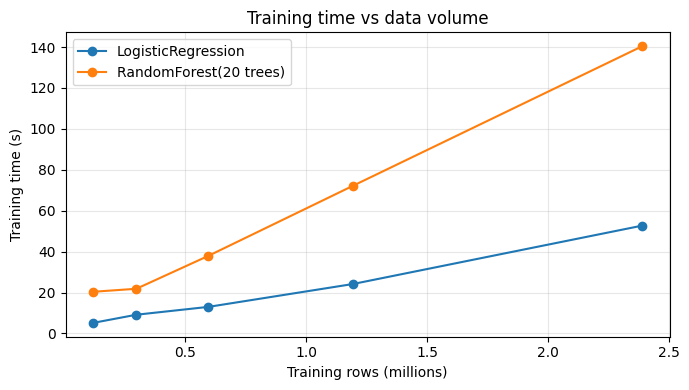

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
for name, g in scal[~scal.projected].groupby("model"):
    ax.plot(g.rows / 1e6, g.seconds, marker="o", label=name)
ax.set(xlabel="Training rows (millions)", ylabel="Training time (s)", title="Training time vs data volume")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/task4_scalability.png", dpi=150); plt.show()

In [14]:
try:
    stages = pd.DataFrame(ui_api("stages?status=complete"))
    stages["duration_s"] = (stages.executorRunTime / 1000).round(2)
    cols = ["stageId", "name", "numTasks", "duration_s", "inputBytes", "shuffleReadBytes", "shuffleWriteBytes",
            "memoryBytesSpilled", "diskBytesSpilled"]
    stages = stages[[c for c in cols if c in stages.columns]]
    for c in ["inputBytes", "shuffleReadBytes", "shuffleWriteBytes", "memoryBytesSpilled", "diskBytesSpilled"]:
        if c in stages.columns:
            stages[c.replace("Bytes", "_MB")] = (stages.pop(c) / 1024**2).round(1)
    top = stages.sort_values("duration_s", ascending=False).head(15)
    print(top.to_string(index=False))
    save_csv(stages, "task4_spark_stages.csv")
    execs = pd.DataFrame(ui_api("executors"))
    print(execs[["id", "totalCores", "maxMemory", "totalTasks", "totalDuration", "totalShuffleRead", "totalShuffleWrite"]].to_string(index=False))
    save_csv(execs[["id", "totalCores", "maxMemory", "totalTasks", "totalDuration", "totalShuffleRead", "totalShuffleWrite"]],
             "task4_executors.csv")
except Exception as e:
    print("Spark UI REST API not reachable here:", e)

 stageId                                                              name  numTasks  duration_s  input_MB  shuffleRead_MB  shuffleWrite_MB  memory_MBSpilled  disk_MBSpilled
      42                          count at NativeMethodAccessorImpl.java:0        16      256.36       0.0          1467.1              0.0               0.0             0.0
     480                                              count at <unknown>:0         5      152.24     227.3             0.0              0.0               0.0             0.0
      40 $anonfun$withThreadLocalCaptured$2 at CompletableFuture.java:1768         7      145.48     311.9             0.0           1467.1               0.0             0.0
     428                          count at NativeMethodAccessorImpl.java:0         5      142.55     227.3             0.0              0.0               0.0             0.0
     376                          count at NativeMethodAccessorImpl.java:0         5      139.66     227.3             0.0        